In [1]:
import json
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

In [2]:
death = pd.read_csv(
    "Deathratebycommunitydistrict.csv"
)

print(death.shape)
print(death.columns.tolist())
death.head()

(59, 4)
['commntydst', 'Total_population', 'Total_Deaths', 'Death_Rate']


,commntydst,Total_population,Total_Deaths,Death_Rate
0,101,78390,181,2.308968
1,102,92445,398,4.305263
2,103,163141,1287,7.888881
3,104,131351,677,5.154129
4,105,63600,254,3.993711


In [3]:
death.info()

death.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 59 entries, 0 to 58
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   commntydst        59 non-null     int64  
 1   Total_population  59 non-null     int64  
 2   Total_Deaths      59 non-null     int64  
 3   Death_Rate        59 non-null     float64
dtypes: float64(1), int64(3)
memory usage: 2.0 KB


commntydst          0
Total_population    0
Total_Deaths        0
Death_Rate          0
dtype: int64

In [4]:
death["commntydst"] = pd.to_numeric(
    death["commntydst"],
    errors="coerce"
).astype("Int64")

death["Total_population"] = pd.to_numeric(
    death["Total_population"],
    errors="coerce"
)

death["Total_Deaths"] = pd.to_numeric(
    death["Total_Deaths"],
    errors="coerce"
)

death["Death_Rate"] = pd.to_numeric(
    death["Death_Rate"],
    errors="coerce"
)

death.head()

,commntydst,Total_population,Total_Deaths,Death_Rate
0,101,78390,181,2.308968
1,102,92445,398,4.305263
2,103,163141,1287,7.888881
3,104,131351,677,5.154129
4,105,63600,254,3.993711


In [5]:
print("Number of records:", len(death))
print("Unique districts:", death["commntydst"].nunique())

print("\nMissing values:")
print(death.isna().sum())

print("\nDuplicate districts:")
print(death["commntydst"].duplicated().sum())

print("\nDeath rate summary:")
print(death["Death_Rate"].describe())

Number of records: 59
Unique districts: 59

Missing values:
commntydst          0
Total_population    0
Total_Deaths        0
Death_Rate          0
dtype: int64

Duplicate districts:
0

Death rate summary:
count    59.000000
mean      6.357455
std       1.636028
min       2.308968
25%       5.285889
50%       6.554282
75%       7.299798
max      11.891098
Name: Death_Rate, dtype: float64


In [6]:
death.sort_values("commntydst")

,commntydst,Total_population,Total_Deaths,Death_Rate
0,101,78390,181,2.308968
1,102,92445,398,4.305263
2,103,163141,1287,7.888881
3,104,131351,677,5.154129
4,105,63600,254,3.993711
5,106,155614,743,4.774635
6,107,222129,1470,6.617776
7,108,231983,1449,6.246147
8,109,110458,644,5.830270
9,110,130440,948,7.267709


In [7]:
with open("nyc_districts.geojson", "r") as file:
    district_shapes = json.load(file)

# Check the geographic identifiers
print(
    district_shapes["features"][0]["properties"]
)

{'commntydst': 101, 'lon': -74.012, 'lat': 40.70738}


In [8]:
for feature in district_shapes["features"]:

    feature["properties"]["commntydst"] = int(
        feature["properties"]["commntydst"]
    )

In [9]:
shape_districts = {
    feature["properties"]["commntydst"]
    for feature in district_shapes["features"]
}

data_districts = set(
    death["commntydst"].dropna().astype(int)
)

print("Missing from GeoJSON:", data_districts - shape_districts)
print("Missing from CSV:", shape_districts - data_districts)

Missing from GeoJSON: set()
Missing from CSV: {480, 481, 226, 227, 164, 356, 484, 228, 482, 355, 483, 595}


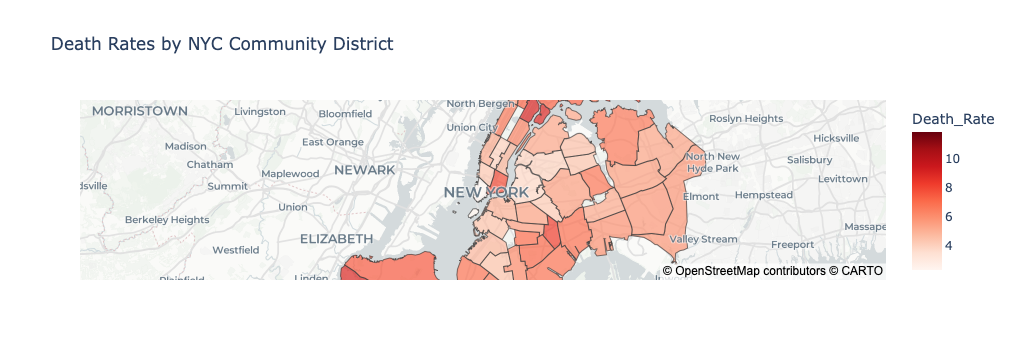

In [10]:
fig = px.choropleth_map(
    death,
    geojson=district_shapes,
    locations="commntydst",
    featureidkey="properties.commntydst",
    color="Death_Rate",
    hover_name="commntydst",
    hover_data={
        "Total_population": True,
        "Total_Deaths": True,
        "Death_Rate": True,
        "commntydst": False
    },
    color_continuous_scale="Reds",
    map_style="carto-positron",
    zoom=9,
    center={
        "lat": 40.7128,
        "lon": -74.0060
    },
    opacity=0.7,
    title="Death Rates by NYC Community District"
)

fig.show()

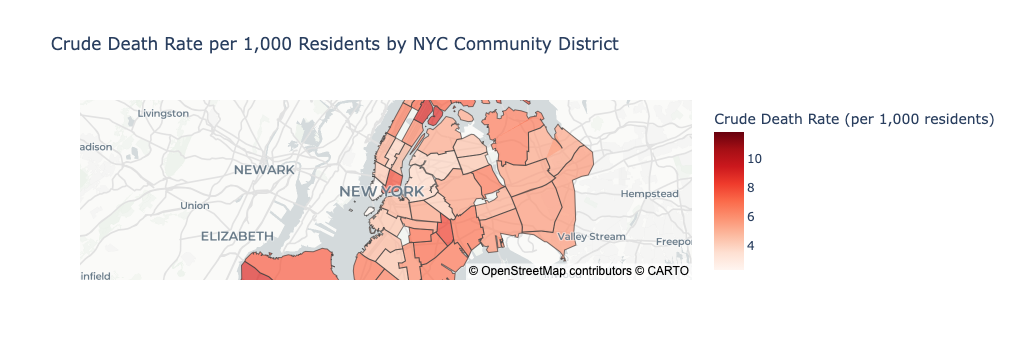

In [11]:
fig = px.choropleth_map(
    death,
    geojson=district_shapes,
    locations="commntydst",
    featureidkey="properties.commntydst",
    color="Death_Rate",
    hover_data={
        "Total_population": True,
        "Total_Deaths": True,
        "Death_Rate": ":.2f"
    },
    color_continuous_scale="Reds",
    map_style="carto-positron",
    zoom=9,
    center={
        "lat": 40.7128,
        "lon": -74.0060
    },
    opacity=0.7,
    labels={
        "Death_Rate": "Crude Death Rate (per 1,000 residents)",
        "Total_population": "Total Population",
        "Total_Deaths": "Total Deaths"
    },
    title="Crude Death Rate per 1,000 Residents by NYC Community District"
)

fig.show()

In [12]:
insurance = pd.read_csv(
    "ZipcodeReportbyProgramandWrittenLanguage.csv",
    dtype={"Zip_Code": str}
)

print(insurance.shape)
print(insurance.columns.tolist())

insurance.head()

(23853, 4)
['Zip Code', 'Program Type', 'Preferred Written Language', 'Number of Enrollments']


,Zip Code,Program Type,Preferred Written Language,Number of Enrollments
0,6390,Medicaid,ENGLISH,*
1,6390,CHP,ENGLISH,*
2,6390,QHP APTC w/o CSR,ENGLISH,*
3,6390,QHP Full Pay,ENGLISH,*
4,6390,Essential Plan,ENGLISH,*


In [16]:
print(insurance.columns.tolist())

['Zip Code', 'Program Type', 'Preferred Written Language', 'Number of Enrollments']


In [17]:
insurance = insurance.rename(columns={
    "Zip Code": "zip",
    "Program Type": "program_type",
    "Preferred Written Language": "language",
    "Number of Enrollments": "enrollments"
})

In [18]:
insurance["zip"] = (
    insurance["zip"]
    .astype(str)
    .str.strip()
    .str.zfill(5)
)

insurance["enrollments"] = pd.to_numeric(
    insurance["enrollments"],
    errors="coerce"
)

print(insurance.shape)
insurance.head()

(23853, 4)


,zip,program_type,language,enrollments
0,06390,Medicaid,ENGLISH,NaN
1,06390,CHP,ENGLISH,NaN
2,06390,QHP APTC w/o CSR,ENGLISH,NaN
3,06390,QHP Full Pay,ENGLISH,NaN
4,06390,Essential Plan,ENGLISH,NaN


In [19]:
with open(
    "nyc-zip-code-tabulation-areas-polygons.geojson",
    "r"
) as file:
    zip_shapes = json.load(file)

print(zip_shapes["features"][0]["properties"])

{'OBJECTID': 1, 'postalCode': '11372', 'PO_NAME': 'Jackson Heights', 'STATE': 'NY', 'borough': 'Queens', 'ST_FIPS': '36', 'CTY_FIPS': '081', 'BLDGpostalCode': 0, 'Shape_Leng': 20624.6923165, 'Shape_Area': 20163283.8744, '@id': 'http://nyc.pediacities.com/Resource/PostalCode/11372'}


In [24]:
nyc_zips = {
    str(feature["properties"]["postalCode"]).zfill(5)
    for feature in zip_shapes["features"]
}

print("Number of NYC ZIP codes:", len(nyc_zips))
print(sorted(nyc_zips)[:10])

Number of NYC ZIP codes: 247
['00083', '10001', '10002', '10003', '10004', '10005', '10006', '10007', '10009', '10010']


In [25]:
insurance["zip"] = (
    insurance["zip"].astype(str).str.strip().str.zfill(5)
)

insurance_nyc = insurance[
    insurance["zip"].isin(nyc_zips)
].copy()

print("Rows in original dataset:", len(insurance))
print("Rows for NYC ZIP codes:", len(insurance_nyc))
print("Unique NYC ZIP codes:", insurance_nyc["zip"].nunique())

Rows in original dataset: 23853
Rows for NYC ZIP codes: 6499
Unique NYC ZIP codes: 222


In [26]:
insurance["zip"] = (
    insurance["zip"].astype(str).str.strip().str.zfill(5)
)

insurance_nyc = insurance[
    insurance["zip"].isin(nyc_zips)
].copy()

print("Rows in original dataset:", len(insurance))
print("Rows for NYC ZIP codes:", len(insurance_nyc))
print("Unique NYC ZIP codes:", insurance_nyc["zip"].nunique())

Rows in original dataset: 23853
Rows for NYC ZIP codes: 6499
Unique NYC ZIP codes: 222


In [27]:
csv_zips = set(insurance_nyc["zip"].unique())

print("ZIP codes in GeoJSON but not CSV:")
print(sorted(nyc_zips - csv_zips))

print("ZIP codes in CSV but not GeoJSON:")
print(sorted(csv_zips - nyc_zips))

ZIP codes in GeoJSON but not CSV:
['00083', '10096', '10097', '10106', '10115', '10121', '10152', '10153', '10154', '10168', '10170', '10171', '10172', '10177', '10178', '10196', '10203', '10259', '10265', '10270', '10271', '10275', '10278', '10281', '10286']
ZIP codes in CSV but not GeoJSON:
[]
